In [8]:
import os

print(os.listdir('/kaggle/input'))

['datasets']


In [9]:
print(os.listdir('/kaggle/input/datasets'))

['dansbecker']


In [17]:
print(os.listdir('/kaggle/input/datasets/dansbecker'))

['food-101']


In [18]:
import os

dataset_path = '/kaggle/input/datasets/dansbecker/food-101'

for root, dirs, files in os.walk(dataset_path):
    level = root.replace(dataset_path, '').count(os.sep)

    if level <= 2:
        print("  " * level + os.path.basename(root) + "/")

        for file in files[:5]:
            print("  " * (level + 1) + file)

food-101/
  food-101.zip
  food-101/
    __MACOSX/
      ._food-101
    food-101/
      .DS_Store
      README.txt
      license_agreement.txt


In [19]:
import os

base_path = '/kaggle/input/datasets/dansbecker/food-101/food-101/food-101'

print("Folders:", os.listdir(base_path))

for folder in os.listdir(base_path):
    path = os.path.join(base_path, folder)
    if os.path.isdir(path):
        print(folder, ":", len(os.listdir(path)), "items")

Folders: ['.DS_Store', 'README.txt', 'images', 'license_agreement.txt', 'meta']
images : 102 items
meta : 6 items


In [22]:
categories = sorted([
    folder for folder in os.listdir(images_path)
    if os.path.isdir(os.path.join(images_path, folder))
    and not folder.startswith('.')
])

print("Number of food categories:", len(categories))

for category in categories[:10]:
    category_path = os.path.join(images_path, category)
    print(category, ":", len(os.listdir(category_path)), "images")

Number of food categories: 101
apple_pie : 1000 images
baby_back_ribs : 1000 images
baklava : 1000 images
beef_carpaccio : 1000 images
beef_tartare : 1000 images
beet_salad : 1000 images
beignets : 1000 images
bibimbap : 1000 images
bread_pudding : 1000 images
breakfast_burrito : 1000 images


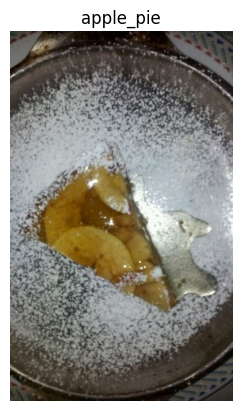

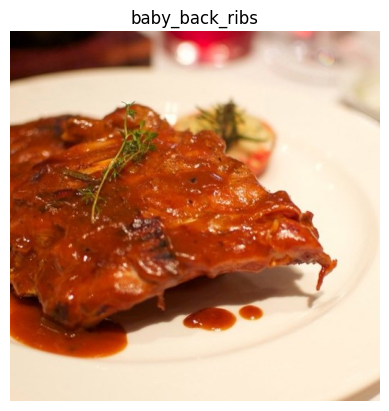

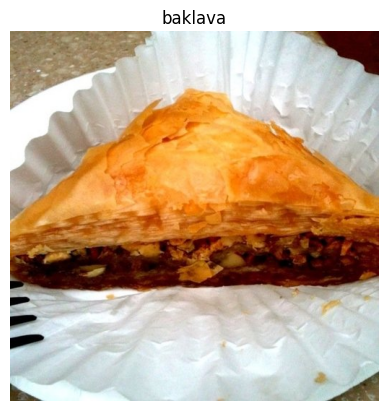

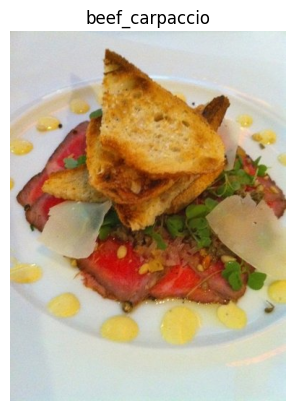

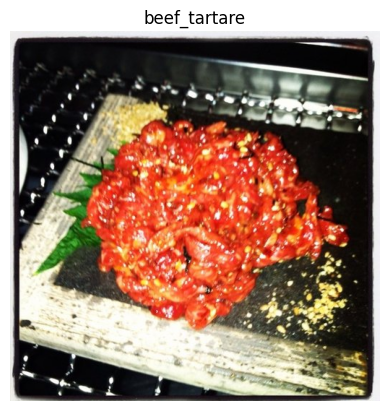

In [23]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import os

for category in categories[:5]:
    category_path = os.path.join(images_path, category)
    image_file = os.listdir(category_path)[0]

    img = mpimg.imread(os.path.join(category_path, image_file))

    plt.imshow(img)
    plt.title(category)
    plt.axis('off')
    plt.show()

In [24]:
import tensorflow as tf

IMG_SIZE = 128
BATCH_SIZE = 32

train_ds = tf.keras.utils.image_dataset_from_directory(
    images_path,
    validation_split=0.2,
    subset="training",
    seed=42,
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    images_path,
    validation_split=0.2,
    subset="validation",
    seed=42,
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE
)

print("Number of classes:", len(train_ds.class_names))
print("Food categories:", train_ds.class_names)

Found 101000 files belonging to 101 classes.
Using 80800 files for training.
Found 101000 files belonging to 101 classes.
Using 20200 files for validation.
Number of classes: 101
Food categories: ['apple_pie', 'baby_back_ribs', 'baklava', 'beef_carpaccio', 'beef_tartare', 'beet_salad', 'beignets', 'bibimbap', 'bread_pudding', 'breakfast_burrito', 'bruschetta', 'caesar_salad', 'cannoli', 'caprese_salad', 'carrot_cake', 'ceviche', 'cheese_plate', 'cheesecake', 'chicken_curry', 'chicken_quesadilla', 'chicken_wings', 'chocolate_cake', 'chocolate_mousse', 'churros', 'clam_chowder', 'club_sandwich', 'crab_cakes', 'creme_brulee', 'croque_madame', 'cup_cakes', 'deviled_eggs', 'donuts', 'dumplings', 'edamame', 'eggs_benedict', 'escargots', 'falafel', 'filet_mignon', 'fish_and_chips', 'foie_gras', 'french_fries', 'french_onion_soup', 'french_toast', 'fried_calamari', 'fried_rice', 'frozen_yogurt', 'garlic_bread', 'gnocchi', 'greek_salad', 'grilled_cheese_sandwich', 'grilled_salmon', 'guacamole',

In [25]:
normalization_layer = tf.keras.layers.Rescaling(1./255)

train_ds = train_ds.map(
    lambda x, y: (normalization_layer(x), y)
)

val_ds = val_ds.map(
    lambda x, y: (normalization_layer(x), y)
)

print("Image normalization completed!")

Image normalization completed!


In [26]:
model = tf.keras.Sequential([

    tf.keras.layers.Input(shape=(128, 128, 3)),

    tf.keras.layers.Conv2D(32, (3,3), activation='relu'),
    tf.keras.layers.MaxPooling2D(2,2),

    tf.keras.layers.Conv2D(64, (3,3), activation='relu'),
    tf.keras.layers.MaxPooling2D(2,2),

    tf.keras.layers.Conv2D(128, (3,3), activation='relu'),
    tf.keras.layers.MaxPooling2D(2,2),

    tf.keras.layers.Flatten(),

    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dropout(0.5),

    tf.keras.layers.Dense(101, activation='softmax')
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 101)            │        13,029 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,317,669 (12.66 MB)

 Trainable params: 3,317,669 (12.66 MB)

 Non-trainable params: 0 (0.00 B)

In [27]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("Model compiled successfully!")

Model compiled successfully!


In [29]:
history = model.fit(
    train_ds,
    epochs=5,
    validation_data=val_ds,
    steps_per_epoch=300,
    validation_steps=75
)

Epoch 1/5
300/300 ━━━━━━━━━━━━━━━━━━━━ 57s 190ms/step - accuracy: 0.0117 - loss: 4.6151 - val_accuracy: 0.0092 - val_loss: 4.6135
Epoch 2/5
300/300 ━━━━━━━━━━━━━━━━━━━━ 11s 37ms/step - accuracy: 0.0117 - loss: 4.6017 - val_accuracy: 0.0167 - val_loss: 4.5611
Epoch 3/5
300/300 ━━━━━━━━━━━━━━━━━━━━ 161s 539ms/step - accuracy: 0.0219 - loss: 4.5461 - val_accuracy: 0.0200 - val_loss: 4.5277
Epoch 4/5
300/300 ━━━━━━━━━━━━━━━━━━━━ 184s 615ms/step - accuracy: 0.0227 - loss: 4.5228 - val_accuracy: 0.0175 - val_loss: 4.4960
Epoch 5/5
300/300 ━━━━━━━━━━━━━━━━━━━━ 182s 610ms/step - accuracy: 0.0248 - loss: 4.4983 - val_accuracy: 0.0312 - val_loss: 4.4968


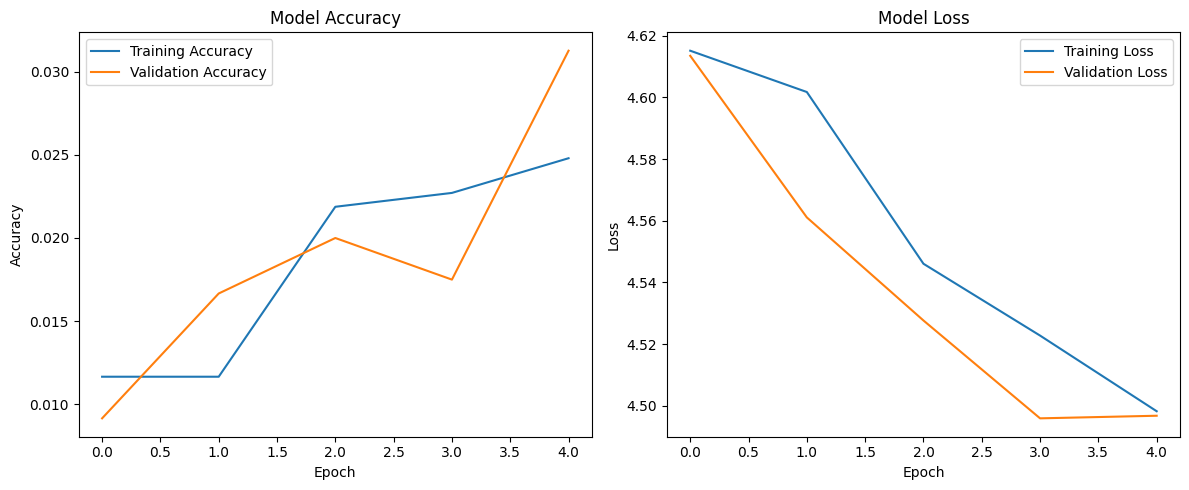

In [31]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1,2,2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

In [32]:
#loading pretrained model mobileNetV2
import tensorflow as tf
from tensorflow.keras import layers, models

IMG_SIZE = 128

base_model = tf.keras.applications.MobileNetV2(
    input_shape=(IMG_SIZE, IMG_SIZE, 3),
    include_top=False,
    weights='imagenet'
)

base_model.trainable = False

model = models.Sequential([
    layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3)),
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dense(256, activation='relu'),
    layers.Dropout(0.4),
    layers.Dense(101, activation='softmax')
])

print("Transfer learning model created!")

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Transfer learning model created!


In [33]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("Model compiled successfully!")

Model compiled successfully!


In [34]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5
)

Epoch 1/5
2525/2525 ━━━━━━━━━━━━━━━━━━━━ 1011s 398ms/step - accuracy: 0.1570 - loss: 3.7609 - val_accuracy: 0.3553 - val_loss: 2.7539
Epoch 2/5
2525/2525 ━━━━━━━━━━━━━━━━━━━━ 95s 38ms/step - accuracy: 0.3002 - loss: 2.9157 - val_accuracy: 0.4164 - val_loss: 2.4114
Epoch 3/5
2525/2525 ━━━━━━━━━━━━━━━━━━━━ 96s 38ms/step - accuracy: 0.3500 - loss: 2.6689 - val_accuracy: 0.4412 - val_loss: 2.2823
Epoch 4/5
2525/2525 ━━━━━━━━━━━━━━━━━━━━ 97s 38ms/step - accuracy: 0.3753 - loss: 2.5387 - val_accuracy: 0.4564 - val_loss: 2.2133
Epoch 5/5
2525/2525 ━━━━━━━━━━━━━━━━━━━━ 97s 38ms/step - accuracy: 0.3941 - loss: 2.4532 - val_accuracy: 0.4609 - val_loss: 2.1685


In [35]:
base_model.trainable = True

# Freeze most layers; train only the last 30
for layer in base_model.layers[:-30]:
    layer.trainable = False

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.00001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("Fine-tuning model ready!")

Fine-tuning model ready!


In [36]:
history_fine = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5
)

Epoch 1/5
2525/2525 ━━━━━━━━━━━━━━━━━━━━ 124s 46ms/step - accuracy: 0.3421 - loss: 2.7113 - val_accuracy: 0.4644 - val_loss: 2.1613
Epoch 2/5
2525/2525 ━━━━━━━━━━━━━━━━━━━━ 115s 45ms/step - accuracy: 0.3958 - loss: 2.4462 - val_accuracy: 0.4790 - val_loss: 2.0783
Epoch 3/5
2525/2525 ━━━━━━━━━━━━━━━━━━━━ 114s 45ms/step - accuracy: 0.4209 - loss: 2.3335 - val_accuracy: 0.4936 - val_loss: 2.0101
Epoch 4/5
2525/2525 ━━━━━━━━━━━━━━━━━━━━ 114s 45ms/step - accuracy: 0.4366 - loss: 2.2519 - val_accuracy: 0.5057 - val_loss: 1.9544
Epoch 5/5
2525/2525 ━━━━━━━━━━━━━━━━━━━━ 114s 45ms/step - accuracy: 0.4542 - loss: 2.1797 - val_accuracy: 0.5155 - val_loss: 1.9171


In [37]:
loss, accuracy = model.evaluate(val_ds)

print("Final Validation Accuracy:", round(accuracy * 100, 2), "%")
print("Final Validation Loss:", round(loss, 4))

632/632 ━━━━━━━━━━━━━━━━━━━━ 19s 30ms/step - accuracy: 0.5155 - loss: 1.9171
Final Validation Accuracy: 51.55 %
Final Validation Loss: 1.9171


1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step


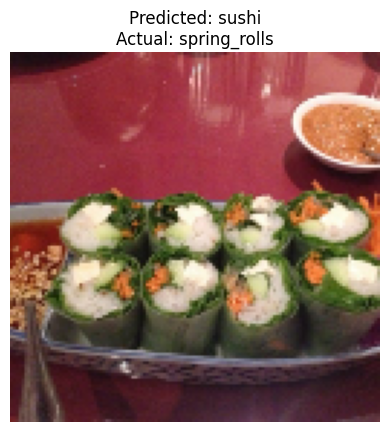

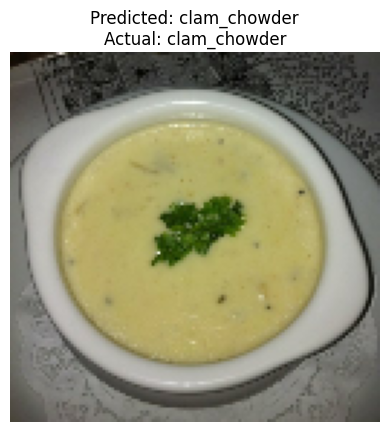

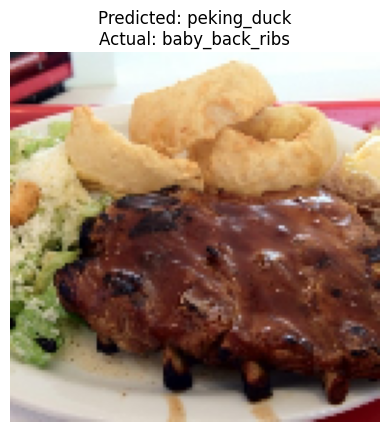

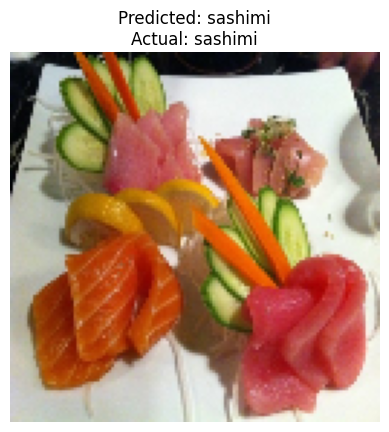

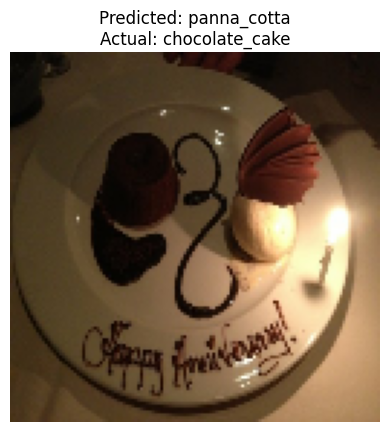

In [39]:
import matplotlib.pyplot as plt
import numpy as np
import os

class_names = sorted([
    folder for folder in os.listdir(base_path + '/images')
    if os.path.isdir(os.path.join(base_path, 'images', folder))
])

for images, labels in val_ds.take(1):
    predictions = model.predict(images[:5])

    for i in range(5):
        predicted_class = np.argmax(predictions[i])
        actual_class = labels[i].numpy()

        plt.imshow(images[i].numpy())
        plt.title(
            f"Predicted: {class_names[predicted_class]}\n"
            f"Actual: {class_names[actual_class]}"
        )
        plt.axis('off')
        plt.show()

In [41]:

#Training
#Complete

#Fine-tuning MobileNetV2
#Complete

#Validation evaluation
#Complete

#Individual image predictions
#Complete

#51.55%
#Validation accuracy across 101 food categories.


In [43]:
model.save('/kaggle/working/food101_mobilenetv2.keras')

print("Model saved successfully!")

Model saved successfully!


In [44]:
import os

print(os.path.exists('/kaggle/working/food101_mobilenetv2.keras'))

True
